# ECG Signal Processing and Heart Rate Analysis

## Project Overview

This project focuses on analyzing real-world Electrocardiogram (ECG) signals using Python.

The main objectives are:
- Loading and visualizing ECG signals.
- Applying digital filters to reduce noise.
- Analyzing frequency components using FFT.
- Detecting R-peaks.
- Calculating RR intervals.
- Estimating heart rate (BPM).

**Dataset:** MIT-BIH Arrhythmia Database  
**Record:** 100  
**Tools:** Python, NumPy, SciPy, Matplotlib, WFDB, Google Colab

In [1]:
!pip install wfdb -q

import wfdb
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load ECG record
record = wfdb.rdrecord('100', pn_dir='mitdb')

# Extract ECG signal
ecg = record.p_signal[:, 0]

# Get sampling frequency
fs = record.fs

print("Sampling Frequency:", fs, "Hz")
print("Number of Samples:", len(ecg))
print("Signal Duration:", len(ecg) / fs, "seconds")

Sampling Frequency: 360 Hz
Number of Samples: 650000
Signal Duration: 1805.5555555555557 seconds


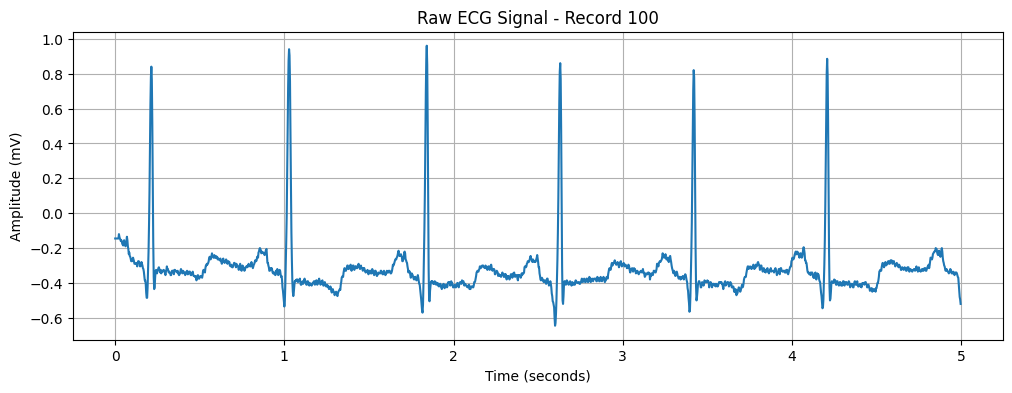

In [3]:
# Create time axis
time = np.arange(len(ecg)) / fs

# Plot first 5 seconds of ECG
plt.figure(figsize=(12, 4))
plt.plot(time[:1800], ecg[:1800])

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("Raw ECG Signal - Record 100")
plt.grid()
plt.show()

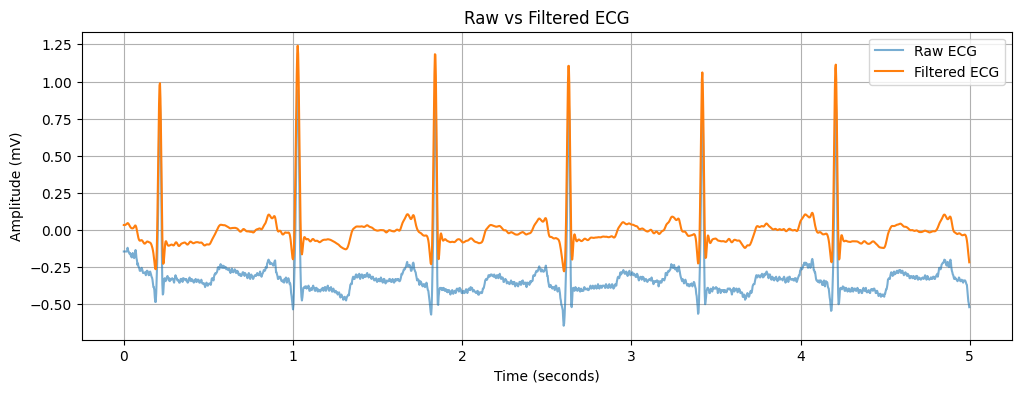

In [4]:
# Design a Butterworth band-pass filter
sos = signal.butter(
    4,
    [0.5, 40],
    btype='bandpass',
    fs=fs,
    output='sos'
)

# Apply the filter
filtered_ecg = signal.sosfiltfilt(sos, ecg)

# Compare raw and filtered signals
plt.figure(figsize=(12, 4))

plt.plot(time[:1800], ecg[:1800], label="Raw ECG", alpha=0.6)
plt.plot(time[:1800], filtered_ecg[:1800], label="Filtered ECG")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("Raw vs Filtered ECG")
plt.legend()
plt.grid()
plt.show()

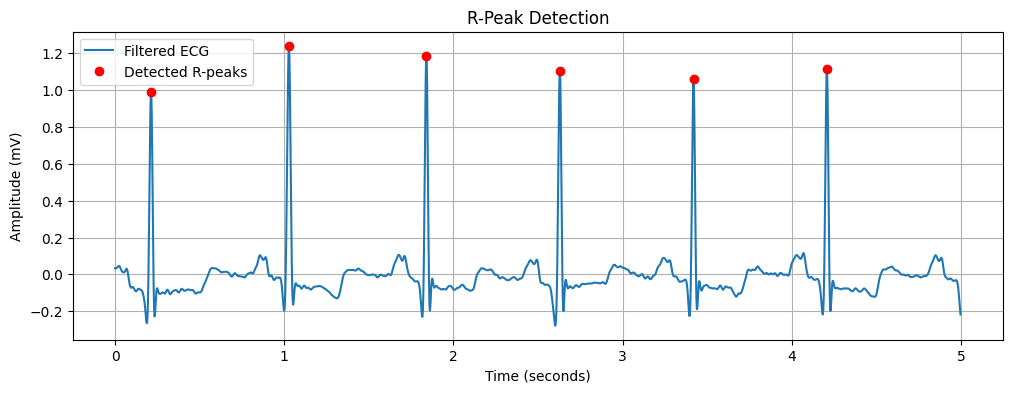

Total detected peaks: 2273


In [5]:
from scipy.signal import find_peaks

# Detect R-peaks in filtered ECG
peaks, properties = find_peaks(
    filtered_ecg,
    distance=int(0.25 * fs),
    prominence=0.5
)

# Plot detected R-peaks
plt.figure(figsize=(12, 4))

plt.plot(time[:1800], filtered_ecg[:1800], label="Filtered ECG")

# Show detected peaks within first 5 seconds
visible_peaks = peaks[peaks < 1800]

plt.plot(
    time[visible_peaks],
    filtered_ecg[visible_peaks],
    "ro",
    label="Detected R-peaks"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("R-Peak Detection")
plt.legend()
plt.grid()
plt.show()

print("Total detected peaks:", len(peaks))

In [6]:
# Calculate R-peak times
peak_times = peaks / fs

# Calculate RR intervals
rr_intervals = np.diff(peak_times)

# Calculate heart rate
heart_rates = 60 / rr_intervals

# Print results
print("First 10 RR Intervals (s):")
print(rr_intervals[:10])

print("\nFirst 10 Heart Rates (bpm):")
print(heart_rates[:10])

print("\nAverage Heart Rate:",
      np.mean(heart_rates), "bpm")

First 10 RR Intervals (s):
[0.81388889 0.81111111 0.79166667 0.78888889 0.78888889 0.81666667
 0.65277778 0.99722222 0.84166667 0.80833333]

First 10 Heart Rates (bpm):
[73.72013652 73.97260274 75.78947368 76.05633803 76.05633803 73.46938776
 91.91489362 60.16713092 71.28712871 74.22680412]

Average Heart Rate: 75.80764604749774 bpm


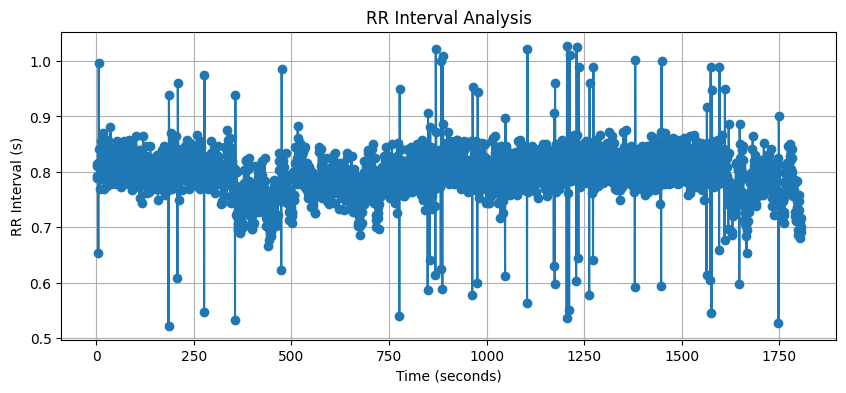

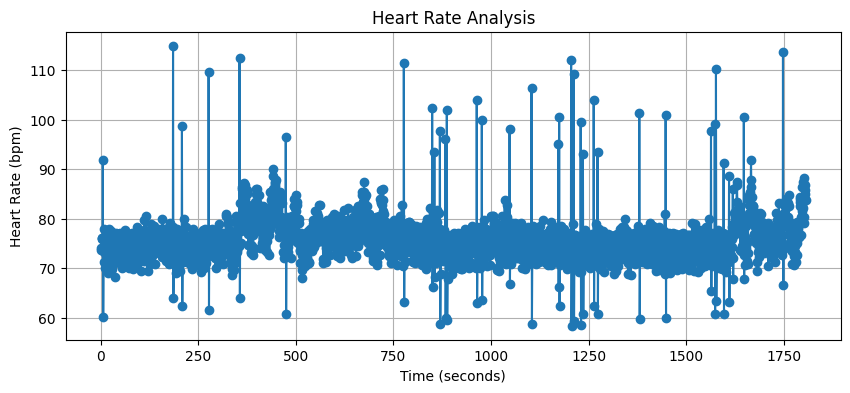

In [7]:
# RR Interval Plot
plt.figure(figsize=(10, 4))
plt.plot(peak_times[1:], rr_intervals, marker='o')

plt.xlabel("Time (seconds)")
plt.ylabel("RR Interval (s)")
plt.title("RR Interval Analysis")
plt.grid()
plt.show()


# Heart Rate Plot
plt.figure(figsize=(10, 4))
plt.plot(peak_times[1:], heart_rates, marker='o')

plt.xlabel("Time (seconds)")
plt.ylabel("Heart Rate (bpm)")
plt.title("Heart Rate Analysis")
plt.grid()
plt.show()

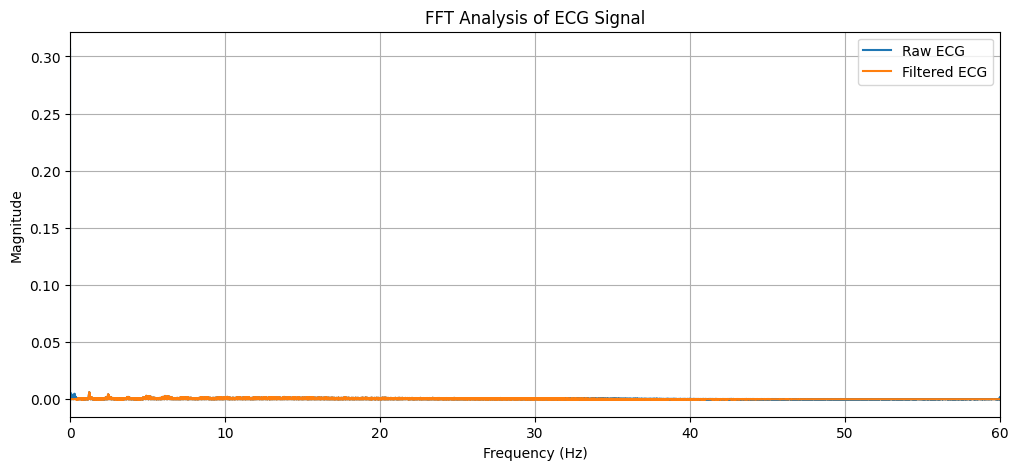

In [8]:
# Number of samples
N = len(ecg)

# FFT of raw and filtered signals
raw_fft = np.fft.rfft(ecg)
filtered_fft = np.fft.rfft(filtered_ecg)

# Frequency axis
frequencies = np.fft.rfftfreq(N, d=1/fs)

# Magnitude spectrum
raw_magnitude = np.abs(raw_fft) / N
filtered_magnitude = np.abs(filtered_fft) / N

# Plot frequency spectra
plt.figure(figsize=(12, 5))

plt.plot(frequencies, raw_magnitude, label="Raw ECG")
plt.plot(frequencies, filtered_magnitude, label="Filtered ECG")

plt.xlim(0, 60)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("FFT Analysis of ECG Signal")
plt.legend()
plt.grid()
plt.show()

## Results

The ECG signal from record 100 of the MIT-BIH Arrhythmia Database was loaded and analyzed using Python.

The main steps of the analysis were:

- Visualization of the raw ECG signal.
- Application of a Butterworth band-pass filter (0.5–40 Hz).
- Detection of R-peaks using the `find_peaks` function.
- Calculation of RR intervals and heart rate.
- Frequency analysis using the Fast Fourier Transform (FFT).

The results show that the filtering process reduces baseline variations while preserving the prominent ECG peaks. RR intervals and heart rate values were calculated from the detected R-peaks.

## Limitations

- The R-peak detection method uses fixed parameters and may not detect every heartbeat correctly.
- The detection results have not yet been validated against the expert annotations.
- The project is intended for educational signal-processing analysis and is not a medical diagnostic system.